# **Conditional Variational Autoencoder (CVAE)**

---

## Why do we need a **Conditional** VAE?

With a standard Variational Autoencoder, we can generate highly realistic, new data, but we have **zero control** over what specifically gets generated. When we sample a random vector from the standard normal distribution and pass it to the decoder, we might get a "3", a "7", or an "8" — it's entirely up to chance. 

What if we want to explicitly tell the network: *"Generate a new, unique handwritten digit, but make sure it is exactly a '5'"*? This is where the **Conditional Variational Autoencoder (CVAE)** comes into play. It allows us to impose specific constraints (conditions) on the generated data.

---

## How does CVAE work?

The core idea is incredibly elegant: we simply pass an **extra piece of information (a condition, usually denoted as $c$)** to both the Encoder and the Decoder. In the case of the MNIST dataset, this condition is the class label (the digit 0-9).

1. **The Encoder ($Q(z|X, c)$)**: Instead of just taking the image $X$ as input, it takes both the image $X$ and the label $c$. It learns to map the image to a probability distribution, *knowing* what digit it is looking at.
2. **The Latent Space**: Because the decoder will also receive the label, the latent space no longer needs to encode *which* digit it is. Instead, it encodes the **style** (e.g., thickness, slant, size).
3. **The Decoder ($P(X|z, c)$)**: It receives the sampled latent vector $z$ (representing the style) AND the label $c$ (representing the identity). It combines them to reconstruct the specific digit in that specific style.

---

## Mathematical and Architectural Nuances

The overall loss function (Reconstruction Loss + KL Divergence) remains exactly the same. The real change happens in the architecture and how tensors are routed:

> **One-Hot Encoding and Concatenation**: Neural networks cannot intuitively process a raw integer label like `7`. Instead, we convert the label into a **One-Hot Vector** (e.g., `[0, 0, 0, 0, 0, 0, 0, 1, 0, 0]` for 10 possible digits). 
> *   **In the Encoder**: We concatenate this one-hot vector to the flattened input image before passing it through the linear layers.
> *   **In the Decoder**: We concatenate the exact same one-hot vector to the sampled latent vector $z$ before decoding.

Because the condition $c$ is provided explicitly, the KL Divergence now forces the latent space to organize purely around structural variations (style, rotation, thickness) rather than class differences.

---

### Applications of CVAEs
- **Targeted Data Generation**: Generating specific classes on demand (e.g., "generate a *red* car", "generate a *smiling* face", or synthesizing specific medical anomalies for research).
- **Image-to-Image Translation**: The condition doesn't have to be a text label; it can be another image. For example, converting a sketch into a photorealistic image (conditioning the output on the sketch).
- **Style Transfer & Attribute Manipulation**: Changing specific attributes of an image while keeping the core identity intact (e.g., changing the lighting of a scene or putting glasses on a portrait without changing the face).

---

In [46]:
import torch
from torch import nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch_directml
import matplotlib.pyplot as plt

## **Linear CVAE Architecture Breakdown**

The `ConditionalVAE` class builds upon the standard linear VAE but introduces a critical new mechanism: **Condition Injection**. To give the network context about what specific digit it is processing or generating, we pass a One-Hot encoded label (the condition, $c$) directly into both the encoder and the decoder.

### 1. The Encoder and `torch.cat`

Instead of accepting just a flattened image of 784 pixels, the `encoder_fc` layer's input dimension is expanded to accommodate the image *plus* the number of classes (784 + 10 = 794). Inside the `encode` method, we use `torch.cat([x, c], dim=1)` to append the 10-dimensional condition vector to the end of our image vector. This allows the network to extract features while explicitly knowing which digit it is looking at.

### 2. The Bottleneck

The computation of the mean ($\mu$), log-variance ($\log(\sigma^2)$), and the reparameterization trick remain exactly the same as in the standard VAE. However, because the encoder already knew the digit's class, it no longer needs to store that information in the latent space. Instead, the latent vector $z$ now purely encodes the *style* (e.g., rotation, thickness, size).

### 3. The Decoder

To reconstruct the image, the decoder needs both the style and the identity. Inside the `decode` method, we again use `torch.cat([z, c], dim=1)` to attach the 10-dimensional condition vector to the 20-dimensional sampled latent vector $z$. The `decoder_fc` layer is expanded to accept this combined 30-dimensional vector, seamlessly transforming the requested digit and style back into a 784-pixel image.

## **Convolutional CVAE Architecture Breakdown**

The `ConvConditionalVAE` introduces the same conditional logic but adapts it for 2D spatial data. Because convolutional layers operate on 3D blocks (channels, height, width) rather than flat vectors, injecting a 1D condition vector requires a clever engineering trick known as **Spatial Conditioning**.

### 1. Spatial Conditioning (Encoder)

We cannot simply concatenate a flat 10-digit vector to a $28 \times 28$ image. Instead, inside the `encode` method, the condition vector is reshaped and stretched. Using `.view()` and `.expand()`, the 10-dimensional One-Hot vector is transformed into **10 separate feature maps** of size $28 \times 28$. For example, if the condition is "3", the third feature map is filled entirely with ones, and the rest with zeros. We then concatenate these 10 condition channels with the 1 image channel, feeding a robust 11-channel tensor into the first `Conv2d` layer.

### 2. Bottleneck Injection (Decoder)

Once the spatial data is downsampled and flattened into the 512-dimensional bottleneck, we revert to the standard flat concatenation. The sampled latent vector $z$ is concatenated with the raw 10-dimensional condition vector.

### 3. The Reverse Spatial Transformation

A dedicated linear layer (`decoder_input`) expands this combined vector back into 512 features. From there, it is reshaped back into a $32 \times 4 \times 4$ 3D tensor. The transposed convolutional layers (`ConvTranspose2d`) then iteratively upsample this feature block until it forms the final conditioned $28 \times 28$ image, bound between 0 and 1 by the final `sigmoid` activation.

In [47]:
class ConditionalVAE(nn.Module):
    # Adding num_classes parameter to the constructor to handle the conditional input
    def __init__(self, input_dim=784, num_classes=10, hidden_dim=400, latent_dim=20):
        super().__init__()
        
        # Encoder
        # Input must accommodate the input image (784) PLUS the condition vector (10) = 794
        self.encoder_fc = nn.Linear(input_dim + num_classes, hidden_dim)
        
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        
        # Decoder
        # Input must accommodate the latent sample (20) PLUS the condition vector (10) = 30
        self.decoder_fc = nn.Linear(latent_dim + num_classes, hidden_dim)
        self.output_out = nn.Linear(hidden_dim, input_dim)

    def encode(self, x, c):
        # x shape: [batch, 784], c shape: [batch, 10]
        # torch.cat concatenates them into a single vector [batch, 794]
        x_cond = torch.cat([x, c], dim=1)
        
        h = F.relu(self.encoder_fc(x_cond))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z, c):
        # z shape: [batch, 20], c shape: [batch, 10]
        # torch.cat concatenates them into a single vector [batch, 30]
        z_cond = torch.cat([z, c], dim=1)
        
        h = F.relu(self.decoder_fc(z_cond))
        return torch.sigmoid(self.output_out(h))

    def forward(self, x, c):
        # Method forward takes both the input x and the condition c
        mu, logvar = self.encode(x, c)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decode(z, c)
        
        return reconstructed, mu, logvar

class ConvConditionalVAE(nn.Module):
    def __init__(self, latent_dim=20, num_classes=10):
        super().__init__()
        self.num_classes = num_classes
        
        # 1. Encoder
        # First layer takes the input image (1 channel) and the condition vector (10 channels) -> 11 channels
        self.encoder = nn.Sequential(
            nn.Conv2d(1 + num_classes, 8, kernel_size=3, stride=2, padding=1),  # -> [batch, 8, 14, 14]
            nn.ReLU(),
            nn.Conv2d(8, 16, kernel_size=3, stride=2, padding=1), # -> [batch, 16, 7, 7]
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1) # -> [batch, 32, 4, 4]
        )
        
        self.flatten_size = 32 * 4 * 4
        
        # 2. Bottleneck
        self.fc_mu = nn.Linear(self.flatten_size, latent_dim)
        self.fc_logvar = nn.Linear(self.flatten_size, latent_dim)
        
        # 3. Decoder
        # Input layer takes the latent vector (20) and the condition vector (10) -> 30
        self.decoder_input = nn.Linear(latent_dim + num_classes, self.flatten_size)
        
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=0),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 8, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(8, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )

    def encode(self, x, c):
        batch_size = x.size(0)
        
        # Spatial Conditioning
        # 1. Reshape the condition vector to [batch, 10, 1, 1]
        # 2. Stretch it to match the spatial dimensions of the input image (28x28) -> [batch, 10, 28, 28]
        c_spatial = c.view(batch_size, self.num_classes, 1, 1).expand(-1, -1, 28, 28)
        
        # Connecting the input image and the condition vector along the channel dimension
        # [batch, 1, 28, 28] + [batch, 10, 28, 28] = [batch, 11, 28, 28]
        x_cond = torch.cat([x, c_spatial], dim=1)
        
        # Forward through the Conv2D layers
        h = self.encoder(x_cond)
        
        # Flattening the output to feed into the fully connected layers for mu and logvar
        h = h.view(batch_size, -1)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z, c):
        # Combining the latent vector and the condition vector
        z_cond = torch.cat([z, c], dim=1)
        
        # Expanding to 512 features
        h = self.decoder_input(z_cond)
        
        # Getting back geometric dimensions for ConvTranspose2D
        h = h.view(h.size(0), 32, 4, 4)
        return self.decoder(h)

    def forward(self, x, c):
        mu, logvar = self.encode(x, c)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decode(z, c)
        return reconstructed, mu, logvar

In [48]:
BATCH_SIZE = 128
EPOCHS = 10
LEARNING_RATE = 1e-3
NUM_CLASSES = 10
DEVICE = torch_directml.device(0)

In [49]:
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)

In [50]:
model = ConvConditionalVAE(latent_dim=20, num_classes=NUM_CLASSES).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [51]:
def vae_loss_function(reconstructed, x, mu, logvar):
    BCE = torch.nn.functional.binary_cross_entropy(reconstructed, x, reduction='sum')
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    
    return BCE + KLD

## **CVAE Training Loop Breakdown**

The training loop for a Conditional VAE operates almost identically to a standard VAE, with one major addition: we must dynamically process the class labels during every batch before feeding them into the network.

### 1. One-Hot Encoding and Type Casting
Neural networks cannot mathematically process raw categorical integers (e.g., treating a "7" as a number). Therefore, we use PyTorch's `F.one_hot()` to convert the batch of labels into a matrix of condition vectors. 

Crucially, `F.one_hot` returns a tensor of integers (`int64`). Because our image tensors and network weights are 32-bit floats, we must explicitly chain the `.float()` method. Without this casting, the network would crash due to a type mismatch when attempting to concatenate or multiply the tensors.

### 2. Hardware Considerations (DirectML)
You will notice that `F.one_hot` is executed on the labels *before* they are sent to the accelerator using `.to(DEVICE)`. This is a specific workaround for the `torch-directml` backend. DirectML currently struggles with the underlying `scatter` operation required to build one-hot vectors directly on the GPU. By performing this operation on the CPU first and transferring the finished matrix to the device, we bypass the error entirely.

### 3. The Unchanged Loss Function
During the forward pass, we provide both the images and the `labels_one_hot` to the model. However, the `vae_loss_function` remains entirely unchanged. It still only takes the `reconstructed` image, the original `images`, `mu`, and `logvar`. This highlights a fundamental CVAE concept: the network is not penalized for failing to "reconstruct" the label. The condition vector serves purely as a directional guide for the encoder and decoder, while the error is still calculated exclusively on pixel accuracy and latent space organization.

In [52]:
model.train()
for epoch in range(EPOCHS):
    train_loss = 0.0
    for images, labels in train_dataloader:
        images = images.to(DEVICE)
        labels_one_hot = F.one_hot(labels, num_classes=NUM_CLASSES).float().to(DEVICE)
        reconstructed, mu, logvar = model(images, labels_one_hot)
        loss = vae_loss_function(reconstructed, images, mu, logvar)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    avg_loss = train_loss / len(train_dataloader.dataset)
    print(f'Epoch [{epoch + 1}/{EPOCHS}], Loss: {avg_loss:.4f}')

Epoch [1/10], Loss: 338.9085
Epoch [2/10], Loss: 260.2142
Epoch [3/10], Loss: 212.6255
Epoch [4/10], Loss: 195.7970
Epoch [5/10], Loss: 186.4363
Epoch [6/10], Loss: 179.7714
Epoch [7/10], Loss: 175.1717
Epoch [8/10], Loss: 171.9995
Epoch [9/10], Loss: 169.9281
Epoch [10/10], Loss: 168.7597


## **Targeted Generation (Inference)**

Now that the Conditional Variational Autoencoder is trained, we can leverage its most powerful feature: generating entirely new data with strict, explicit constraints. Just like in the standard VAE, we bypass the encoder completely and interact directly with the decoder.

### 1. Fixing the Identity (The Condition Vector)

Unlike the standard VAE where we had no control over the output, here we explicitly define the `target_digit` we want the model to generate (e.g., the number "8"). We use `torch.full` to create an array of identical labels and process them through `F.one_hot`. This creates our condition matrix $c$, serving as a strict instruction to the decoder: *"No matter what else you receive, draw an 8."*

### 2. Exploring the Style (The Latent Space)

While the condition vector dictates *what* to draw, the latent vector $z$ now dictates *how* to draw it. We sample 5 completely random vectors from a Standard Normal Distribution. Because the network learned to separate the digit's identity from its structural features during training, these random coordinates now represent varying structural styles (e.g., line thickness, tilt, loop size, or openness). 

When we pass both the random styles ($z$) and the fixed condition ($c$) into the decoder, the result is a batch of five distinct, unique versions of the digit "8".

### 3. Tensor Reshaping

Finally, we must format the decoder's output for visualization. A convolutional decoder outputs a 4D tensor formatted as `[batch, channels, height, width]` (e.g., `[5, 1, 28, 28]`). Matplotlib expects a 2D grid for a grayscale image. Instead of flattening and reshaping the entire image with `.view()`, we use `.squeeze(1)`. This elegantly drops the redundant channel dimension, resulting in a `[5, 28, 28]` tensor that can be safely converted to a NumPy array and plotted.

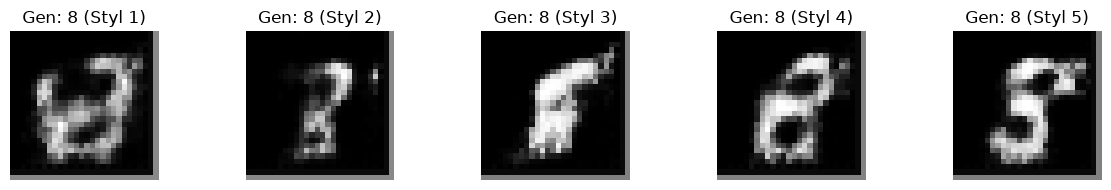

In [53]:
model.eval()
with torch.no_grad():
    # Defining the number of samples to generate and the target digit
    num_samples = 5
    target_digit = 8

    # 1. Preparing the condition vector for the target digit
    labels = torch.full((num_samples,), target_digit, dtype=torch.long)
    labels_one_hot = F.one_hot(labels, num_classes=NUM_CLASSES).float().to(DEVICE)

    # 2. Randomly choosing styles (latent vectors) for the target digit
    z_random = torch.randn(num_samples, 20).to(DEVICE)

    # 3. Decoding the latent vectors with the condition to generate images
    generated_images = model.decode(z_random, labels_one_hot)

    # --- TENSOR RESHAPING ---
    # For linear model: reshape from flat vector [5, 784] to images [5, 28, 28]
    # generated_images = generated_images.view(num_samples, 28, 28).cpu().numpy()
    
    # For convolutional model: remove the channel dimension [5, 1, 28, 28] -> [5, 28, 28]
    generated_images = generated_images.squeeze(1).cpu().numpy()


fig, axes = plt.subplots(1, num_samples, figsize=(12, 2))
for i in range(num_samples):
    axes[i].imshow(generated_images[i], cmap='gray')
    axes[i].axis('off')
    axes[i].set_title(f"Gen: {target_digit} (Styl {i+1})")

plt.tight_layout()
plt.show()

## **Model Output Analysis & Conclusions**

* **Successful Conditioning:** The output clearly demonstrates that the CVAE has successfully learned to disentangle the class identity from its structural style. By explicitly passing the condition vector for the digit "8", every single generated image belongs to the requested class, providing the exact targeted control that standard VAEs lack.
* **Style Variation:** While the condition fixes the numerical identity, the random latent vectors ($z$) successfully drive the geometric variations. We can observe distinct structural styles across the batch: some eights are upright and thick, others are slanted, and some feature open loops that slightly resemble a "S" or a "5". The latent space now functions purely as a continuous "style dictionary" rather than a map of distinct classes.
* **Inherent VAE Blurriness:** The generated digits still exhibit the characteristic visual softness typical of Variational Autoencoders. Because the network optimizes Kullback-Leibler divergence (which forces probability distributions to overlap) alongside a pixel-wise reconstruction loss, it inherently averages out structural uncertainties, resulting in blurred edges rather than crisp, high-frequency details.

## Key Takeaways

1. **A CVAE conditions both encoder and decoder on the class label,** enabling generation of a requested digit rather than an uncontrolled class.
2. **One-hot labels are concatenated with image features in the encoder and with latent vectors in the decoder.** The latent vector can therefore focus more on style and shape variation.
3. **The VAE objective still combines reconstruction and KL terms,** and generation samples latent vectors while keeping the target label fixed.
4. **Conditioning improves control, not necessarily sharpness:** samples can still be blurry, and imperfect latent separation can produce ambiguous shapes.